# Assesment Notebook

In [1]:
# Install packages

%pip install pandas scikit-learn numpy matplotlib seaborn 

Note: you may need to restart the kernel to use updated packages.


## Problem 1: Exploring Petal Length

Importing iris data set and analyzing.

In [2]:
# Import iris
import pandas as pd
from sklearn.datasets import load_iris

# Load the iris dataset.
X = pd.read_csv('https://gist.githubusercontent.com/curran/a08a1080b88344b0c8a7/raw/0e7a9b0a5d22642a06d3d5b9bcbad9890c8ee534/iris.csv')

# Load the dataset.
iris = load_iris()

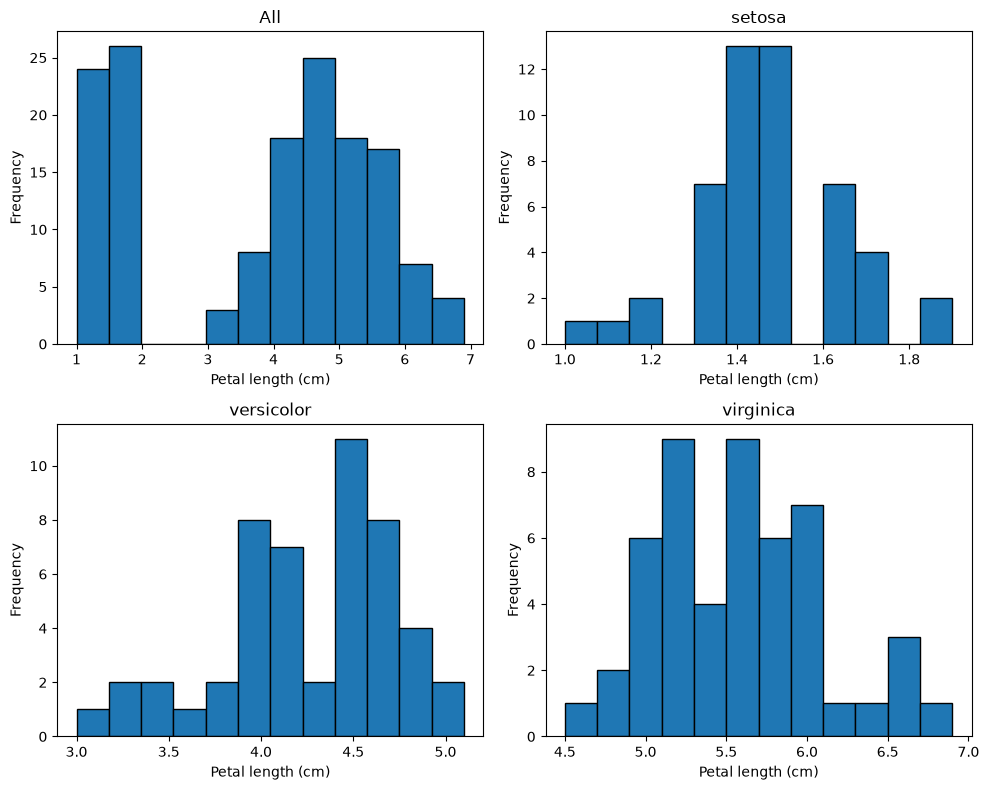

In [3]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

# Cargar los datos
iris = load_iris(as_frame=True)
df = iris.frame

# Añadir los nombres de las especies
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))

# Crear los gráficos
plt.figure(figsize=(10, 8))

for i, species in enumerate(["All", "setosa", "versicolor", "virginica"]):

    if species == "All":
        data = df["petal length (cm)"]
    else:
        data = df[df["species"] == species]["petal length (cm)"]

    plt.subplot(2, 2, i + 1)
    plt.hist(data, bins=12, edgecolor="black")

    plt.title(species)
    plt.xlabel("Petal length (cm)")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## Problem 2

Correlation Between Petal Length and Petal Width
In this problem I am doing a deeper analisys comparing the relantionship between Petal length and Petal width from the iris data set.

In [4]:

from scipy.stats import pearsonr

# Calculate Pearson correlation for all 150 flowers
r, p_value = pearsonr(
    df["petal length (cm)"],
    df["petal width (cm)"]
)

print(f"Pearson correlation coefficient: {r:.4f}")
print(f"P-value: {p_value:.6g}")



Pearson correlation coefficient: 0.9629
P-value: 4.675e-86


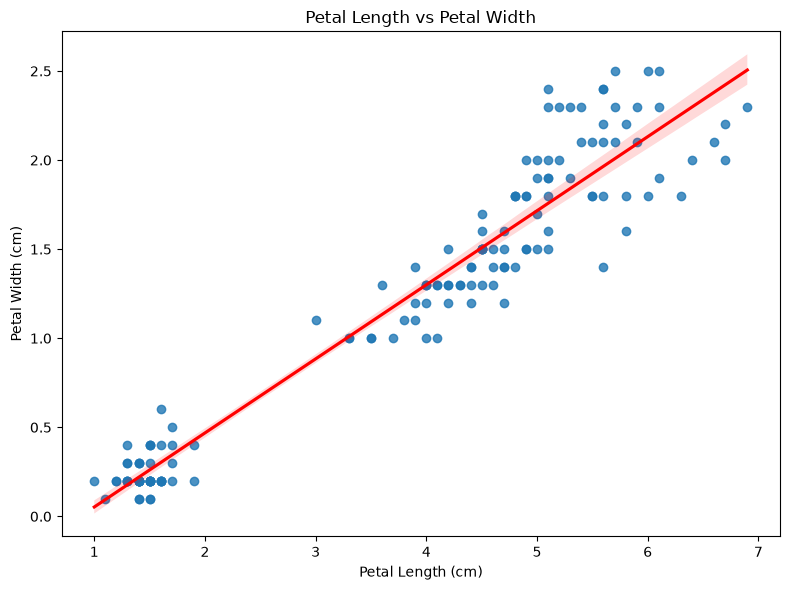

In [5]:

import seaborn as sns

plt.figure(figsize=(8, 6))

sns.regplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    line_kws={"color": "red"}
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.tight_layout()
plt.show()


In [6]:

# Calculate Pearson correlation separately for each species

for species, group in df.groupby("species"):
    r, p_value = pearsonr(
        group["petal length (cm)"],
        group["petal width (cm)"]
    )

    print(f"{species}: r = {r:.4f}")


setosa: r = 0.3316
versicolor: r = 0.7867
virginica: r = 0.3221


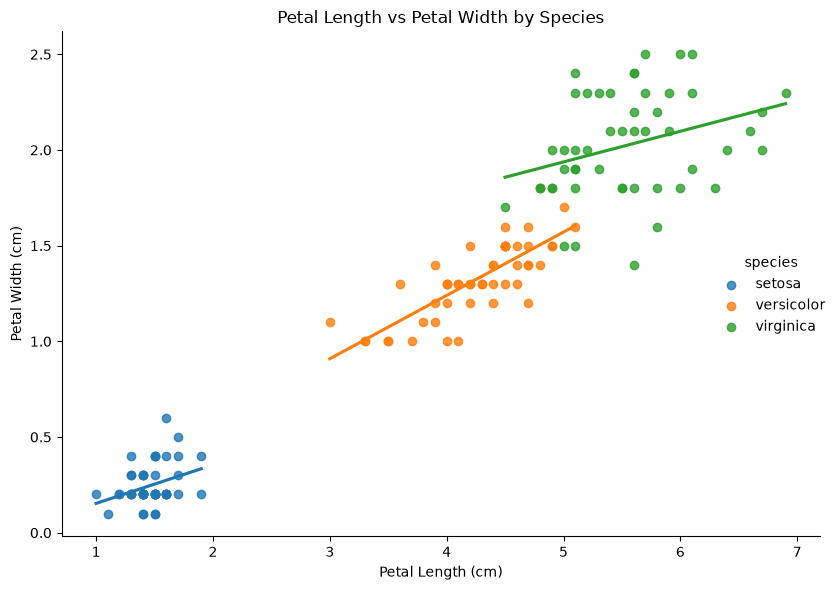

In [7]:

sns.lmplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    ci=None,
    height=6,
    aspect=1.2
)

plt.title("Petal Length vs Petal Width by Species")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.tight_layout()
plt.show()


In [8]:

results = []

# Overall correlation
r, p_value = pearsonr(
    df["petal length (cm)"],
    df["petal width (cm)"]
)

results.append({
    "Species": "All flowers",
    "Pearson correlation": round(r, 4)
})

# Correlation for each species
for species, group in df.groupby("species"):
    r, p_value = pearsonr(
        group["petal length (cm)"],
        group["petal width (cm)"]
    )

    results.append({
        "Species": species,
        "Pearson correlation": round(r, 4)
    })

correlation_table = pd.DataFrame(results)
print(correlation_table.to_string(index=False))


    Species  Pearson correlation
All flowers               0.9629
     setosa               0.3316
 versicolor               0.7867
  virginica               0.3221


## Problem 3